# Redes Neuronales

## Tarea 4: Generar una ANN del problema de Palmer Penguins

En esta tarea vamos a hacer una red neuronal que tenga como meta identificar la especie de un pingüino en base a sus atributos físicos (peso y tamaño del pico y aletas)

### Importar las librerías

Vamos a usar pandas, Scikitlearn para la estandarización y la codificaión, seaborn para cargar el dataset de forma más facil y para realizar una matriz de confusión, y evidentemente TensorFlow para la red neuronal.



In [95]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf

Aqui cargamos el dataset que se incluye en la biblioteca de Seaborn

In [96]:
df = sns.load_dataset('penguins')

In [97]:
df.shape  #Verificamos las dimensiones del Dataframe

(344, 7)

In [98]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [99]:
df = df.dropna() #Eliminamos las filas con datos nulos
df.shape

(333, 7)

Los datos que conforman a X son todos, menos la etiqueta, esta última corresponde a y.

In [100]:
X = df.drop('species', axis=1)
y = df['species']

In [101]:
X.head()

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Torgersen,39.3,20.6,190.0,3650.0,Male


In [102]:
y.head()

,species
0,Adelie
1,Adelie
2,Adelie
4,Adelie
5,Adelie


Binarizamos las variables no numéricas, en este caso la isla y el sexo, para el caso de la isla hay tres opciones (Biscoe, Dream, Togersen) y para el sexo hay dos.

In [103]:
X = pd.get_dummies(X, columns=['island', 'sex'])

In [104]:
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
0,39.1,18.7,181.0,3750.0,False,False,True,False,True
1,39.5,17.4,186.0,3800.0,False,False,True,True,False
2,40.3,18.0,195.0,3250.0,False,False,True,True,False
4,36.7,19.3,193.0,3450.0,False,False,True,True,False
5,39.3,20.6,190.0,3650.0,False,False,True,False,True


Para las etiquetas (y) usamos el encoder, ya que el resultado sólo puede ser un nḿero.

In [105]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [106]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,

Dividimos el conjunto de datos (80% para entrenamiento, train), y el restante para las pruebas (test), usamos Stratify porque nuestra variable objetivo está desbalanceada, es decir, las especies de pingüinos no están en la misma proporción, entonces para asegurar que haya la misma prporcion tanto en el conjunto de prueba como en el de entrenamiento usamos este parámetro.

Otra cosa que me parece importante resaltar, es que esto lo estamos haciendo antes de hacer la estandarización, para prevenir el data Leakeage.

In [107]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Verificamos el tamaño de nuestros conuntos.

In [108]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(266, 9)
(67, 9)
(266,)
(67,)


Una vez teniendo los datos divididos, ahora sí podemos estandarizar.
IMPORTANTE: para entrenar el Scaler, lo hacemos con el conjunto de datos de entrenamiento (X_train), de nuevo para evitar hacer Data Leakage

In [109]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [110]:
pd.DataFrame(X_train).head()

,0,1,2,3,4,5,6,7,8
0,0.167325,-1.992311,0.834781,1.082394,1.038328,-0.769944,-0.414495,1.046178,-1.046178
1,1.227050,1.255521,0.121247,-0.215642,-0.963087,1.298795,-0.414495,-0.955860,0.955860
2,0.879899,-0.520638,1.476961,2.194997,1.038328,-0.769944,-0.414495,-0.955860,0.955860
3,-0.472164,0.646552,0.049894,-0.431982,-0.963087,-0.769944,2.412574,-0.955860,0.955860
4,-1.166467,1.052531,-1.448527,-1.142811,-0.963087,1.298795,-0.414495,1.046178,-1.046178


In [111]:
X_train.shape

(266, 9)

## Red Neuronal

La secuencia de pasos que hay que hacer es:
1. Disear la red neuronal
2. Configurar la red neuronal
3. Entrenar el modelo
4. Evaluar el rendimiento del modelo (imporatnte seleccionar que métrica usar)
5. Hacer una predicción.

Para el diseo vamos a tener 9 neuronas de entrada, este parametro no lo ponemos implicitamente, sino que usando el metodo shape de pandas, podemos obtener ese número.
Y la función de activación que vamos a utilizar es la Sigmoide, con tres salidas, según la especie de pingüino que tengamos.

In [112]:
# 1. Diseñar la red neuronal
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units = 3, activation = "sigmoid")
])

Configuramos la red neuronal con compile.
Como función de perdida vamos a utilizar la Entropia Cruzada, y en este caso al ser un problema de categorización no binaria usamos "sparse_categorical_crossentropy"
El optimizador va a ser SGD, Gradiente de Descenso Estocástico, y el parametro alpha ó tasa de aprendizaje (Learning Ratio) va a ser de $α=0.1$

In [118]:
# 2. Configurar la red neuronal
model.compile(
    loss = "sparse_categorical_crossentropy",
    optimizer = tf.keras.optimizers.SGD(learning_rate = 0.1),
    metrics=["accuracy"]
)

Entrenamos el modelo con la porción de datos que en el preprocesamiento definimos, y para este caso vamos a usar 300 iteraciones o épocas.

In [119]:
# 3. Entrenar modelo
model.fit(X_train, y_train, epochs = 300, verbose = 0)

In [120]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión final en el conjunto de prueba: {accuracy:.4f}")


Precisión final en el conjunto de prueba: 0.9851


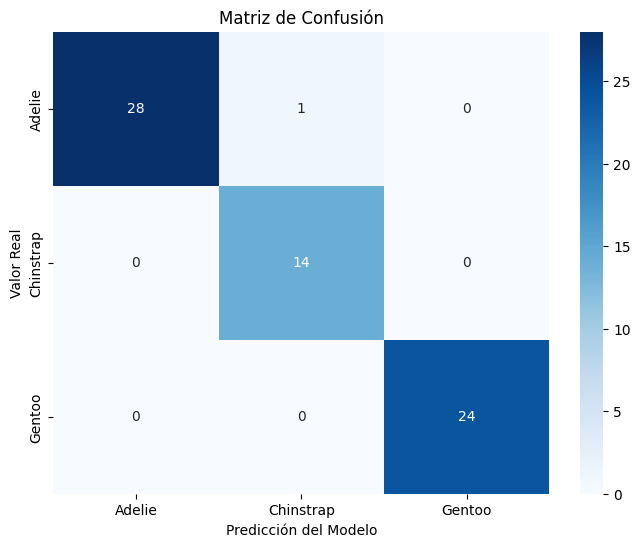

In [122]:
import matplotlib.pyplot as plt

# 1. Obtener las predicciones para todo el conjunto de prueba
predictions = model.predict(X_test, verbose=0)
y_pred = predictions.argmax(axis=-1)

# 2. Calcular y graficar la matriz de confusión
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues', xticklabels=encoder.classes_, yticklabels=encoder.classes_)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()